# Vacuum Systems Guide

Python companion to the AMO Toolkit page [Vacuum Systems Guide](https://amotoolkit.com/pages/vacuum-systems.html). It reproduces the page's calculator with the same constants and formulas, so you can change anything, script a scan, or check a number in your own analysis.

[Open in Colab](https://colab.research.google.com/github/saumitraphatak/amo-career/blob/main/notebooks/vacuum-systems.ipynb) · needs only `numpy`, `scipy` and `matplotlib`.

## 1. What a pressure means for the atoms
Ideal gas at 293 K: density $n = P/k_BT$; N₂ mean free path $\lambda = k_BT/(\sqrt2\pi d^2 P)$ with d = 3.7 Å; and a background-collision lifetime $\tau = 1/(n\sigma v)$ with σ ≈ 3×10⁻¹⁸ m² and v̄ ≈ 470 m/s, which reproduces the rule of thumb τ ≈ 2×10⁻⁸ Torr·s / P (Arpornthip, Sackett & Hughes 2012). Real lifetimes depend on the gas mix (mostly H₂ in a baked system) and the trap depth.

{'P_Torr': '7.5e-11', 'n_cm3': '2.47e+06', 'mfp_km': '665', 'tau_min': '4.78'}

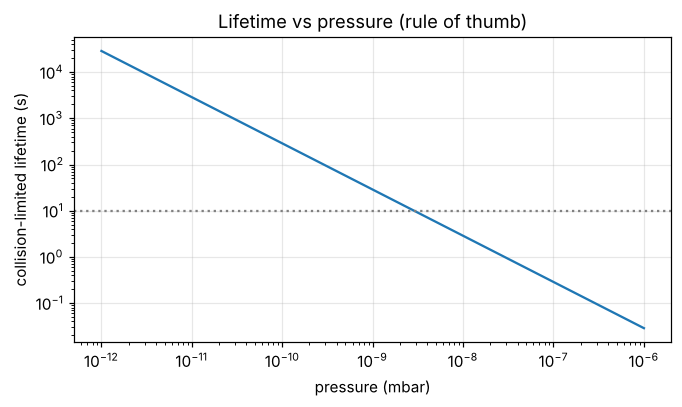

In [1]:
import numpy as np
import matplotlib.pyplot as plt
kB, T = 1.380649e-23, 293

def pressure(P_mbar):
    Pa = P_mbar * 100; n = Pa / (kB * T)
    return dict(P_Torr=P_mbar * 0.750062, n_cm3=n * 1e-6, mfp_km=kB * T / (np.sqrt(2) * np.pi * (3.7e-10) ** 2 * Pa) / 1e3,
                tau_min=1 / (n * 3e-18 * 470) / 60)

r = pressure(1e-10)     # the page's default, 10⁻¹⁰ mbar
print({k: f"{v:.3g}" for k, v in r.items()})
P = np.logspace(-12, -6, 100)
plt.loglog(P, [pressure(p)["tau_min"] * 60 for p in P]); plt.axhline(10, ls=":", c="gray")
plt.xlabel("pressure (mbar)"); plt.ylabel("collision-limited lifetime (s)"); plt.title("Lifetime vs pressure (rule of thumb)")

## 2. Conductance-limited pumping (molecular flow)
A tube between chamber and pump adds in series like a resistor: $1/S_\mathrm{eff} = 1/S + 1/C$. Entrance aperture $C_{ap} = 11.6\,A$ L/s (A in cm²) in series with the long-tube $C_t = 12.1\,d^3/L$ L/s (d, L in cm), both scaled by $\sqrt{29/M}$ for other gases (Pfeiffer Vacuum Know-How, Eqs. 1-21, 1-25, 1-31).

{'C': np.float64(33.12), 'C_aperture': np.float64(131.56), 'C_tube': np.float64(44.26), 'S_eff': np.float64(24.88), 'pressure_factor': np.float64(4.02), 'L_half_mm': np.float64(15.93)}
N₂: S_eff = 25 L/s (the pump's own speed for each gas differs too; use its datasheet)
H₂: S_eff = 56 L/s (the pump's own speed for each gas differs too; use its datasheet)

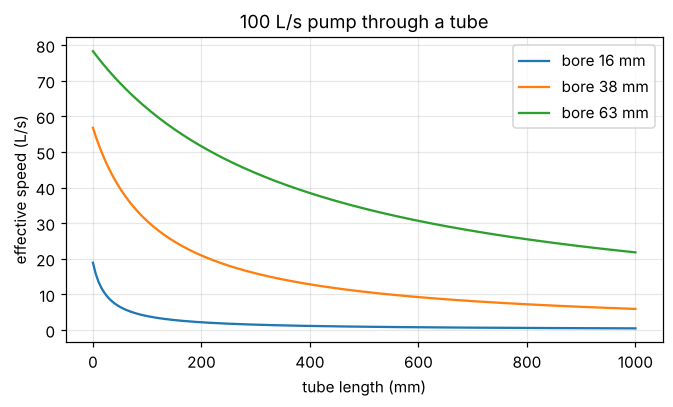

In [2]:
def conductance(d_mm, L_mm, M=28.96):
    g = np.sqrt(28.96 / M); d, L = d_mm / 10, L_mm / 10
    Cap = 11.6 * np.pi * d**2 / 4 * g
    Ct = 12.1 * d**3 / L * g if L > 0 else np.inf
    return 1 / (1 / Cap + 1 / Ct), Cap, Ct

def pumping(S=100, d_mm=38, L_mm=150, M=28.96):
    C, Cap, Ct = conductance(d_mm, L_mm, M); Se = 1 / (1 / S + 1 / C)
    L_half = 12.1 * (d_mm / 10) ** 3 * np.sqrt(28.96 / M) * (1 / S - 1 / Cap) * 10
    return dict(C=C, C_aperture=Cap, C_tube=Ct, S_eff=Se, pressure_factor=S / Se, L_half_mm=L_half)

p = pumping()     # page defaults
print({k: round(v, 2) for k, v in p.items()})
for gas, M in (("N₂", 28.96), ("H₂", 2.016)):
    print(f"{gas}: S_eff = {pumping(M=M)['S_eff']:.0f} L/s (the pump's own speed for each gas differs too; use its datasheet)")
L = np.linspace(0, 1000, 200)
for d in (16, 38, 63):
    plt.plot(L, [pumping(d_mm=d, L_mm=l)["S_eff"] for l in L], label=f"bore {d} mm")
plt.xlabel("tube length (mm)"); plt.ylabel("effective speed (L/s)"); plt.legend(); plt.title("100 L/s pump through a tube")

## 3. Check against the page

In [3]:
def check(ours, page, rel=0.006):
    """Compare our numbers with the values the web page shows at its default settings."""
    bad = []
    for k, shown in page.items():
        v = ours[k]
        ok = abs(v - shown) <= rel * abs(shown) + 1e-12 or abs(v - shown) <= 0.5 * 10 ** -DECIMALS.get(k, 99)
        print(f"{k:>12}: notebook {v:<12.4g} page {shown:<10g} {'OK' if ok else 'MISMATCH'}")
        if not ok: bad.append(k)
    assert not bad, f"differs from the page: {bad}"
    print("All values match the page.")

ours = dict(n_cm3=r["n_cm3"], mfp_km=r["mfp_km"], tau_min=r["tau_min"], C=p["C"], C_aperture=p["C_aperture"], C_tube=p["C_tube"],
            S_eff=p["S_eff"], factor=p["pressure_factor"], L_half_mm=p["L_half_mm"])
DECIMALS = dict(mfp_km=0, tau_min=1, C=1, C_aperture=0, C_tube=1, S_eff=1, factor=2, L_half_mm=0)
page = dict(n_cm3=2.5e6, mfp_km=665, tau_min=4.8, C=33.1, C_aperture=132, C_tube=44.3, S_eff=24.9, factor=4.02, L_half_mm=16)
check(ours, page, rel=0.02)   # the page prints the density as 2.5×10⁶

       n_cm3: notebook 2.472e+06    page 2.5e+06    OK
      mfp_km: notebook 665.1        page 665        OK
     tau_min: notebook 4.782        page 4.8        OK
           C: notebook 33.12        page 33.1       OK
  C_aperture: notebook 131.6        page 132        OK
      C_tube: notebook 44.26        page 44.3       OK
       S_eff: notebook 24.88        page 24.9       OK
      factor: notebook 4.019        page 4.02       OK
   L_half_mm: notebook 15.93        page 16         OK
All values match the page.